<a href="https://colab.research.google.com/github/dimi-kri/ML-Ergasia2/blob/main/Ergasia_2_KNN_Timeseries_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Εργασία 2 – K-Nearest Neighbors & Timeseries Forecasting

## Βιβλιοθήκες

In [9]:
import time
import warnings
import contextlib
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

import yfinance as yf
import holidays
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

# Μέρος 1 – KNN



## Ερώτημα 1.1 – Φόρτωση δεδομένων και κατανομές μεταβλητών

In [10]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
df

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,3,4,3,3,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,2,3,5,2,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,4,4,5,4,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,2,3,4,2,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,3,3,5,3,3,4,4,5,4,3,3,3,3,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,4,4,4,2,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,3,5,3,4,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,2,4,2,1,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,4,3,4,1,4,4,5,3,3,4,5,3,5,Satisfied


In [11]:
data_dict = pd.read_csv('airlines_data_dictionary.csv')
data_dict

,Field,Description
0,ID,Unique passenger identifier
1,Gender,Gender of the passenger (Female/Male)
2,Age,Age of the passenger
3,Customer Type,Type of airline customer (First-time/Returning)
4,Type of Travel,Purpose of the flight (Business/Personal)
5,Class,Travel class in the airplane for the passenger...
6,Flight Distance,Flight distance in miles
7,Departure Delay,Flight departure delay in minutes
8,Arrival Delay,Flight arrival delay in minutes
9,Departure and Arrival Time Convenience,Satisfaction level with the convenience of the...


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  object 
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  object 
 4   Type of Travel                          129880 non-null  object 
 5   Class                                   129880 non-null  object 
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Online Booking                  1298

In [13]:
cat_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Satisfaction']
num_cols = [c for c in df.columns if c not in cat_cols + ['ID']]
print(len(cat_cols), 'κατηγορικές:', cat_cols)
print(len(num_cols), 'αριθμητικές:', num_cols)

5 κατηγορικές: ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Satisfaction']
18 αριθμητικές: ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']


In [14]:
missing = df.isna().sum()
missing[missing > 0]

,0
Arrival Delay,393


**Παρατηρήσεις:**

* Έχουμε 129.880 γραμμές (επιβάτες) και 24 στήλες.
* Η στήλη ID είναι απλώς ένας αύξων αριθμός που δεν λέει τίποτα για την ικανοποίηση, οπότε θα την αφαιρέσουμε.
* Οι κατηγορικές μεταβλητές είναι 5: Gender, Customer Type, Type of Travel, Class και ο στόχος Satisfaction.
* Οι αριθμητικές είναι 18: ηλικία, απόσταση πτήσης, δύο καθυστερήσεις και 14 βαθμολογίες εξυπηρέτησης από 0 έως 5 (το 0 σημαίνει δεν απαντήθηκε).
* Λείπουν 393 τιμές μόνο στη στήλη Arrival Delay (τα κελιά είναι κενά).

### Ιστογράμματα

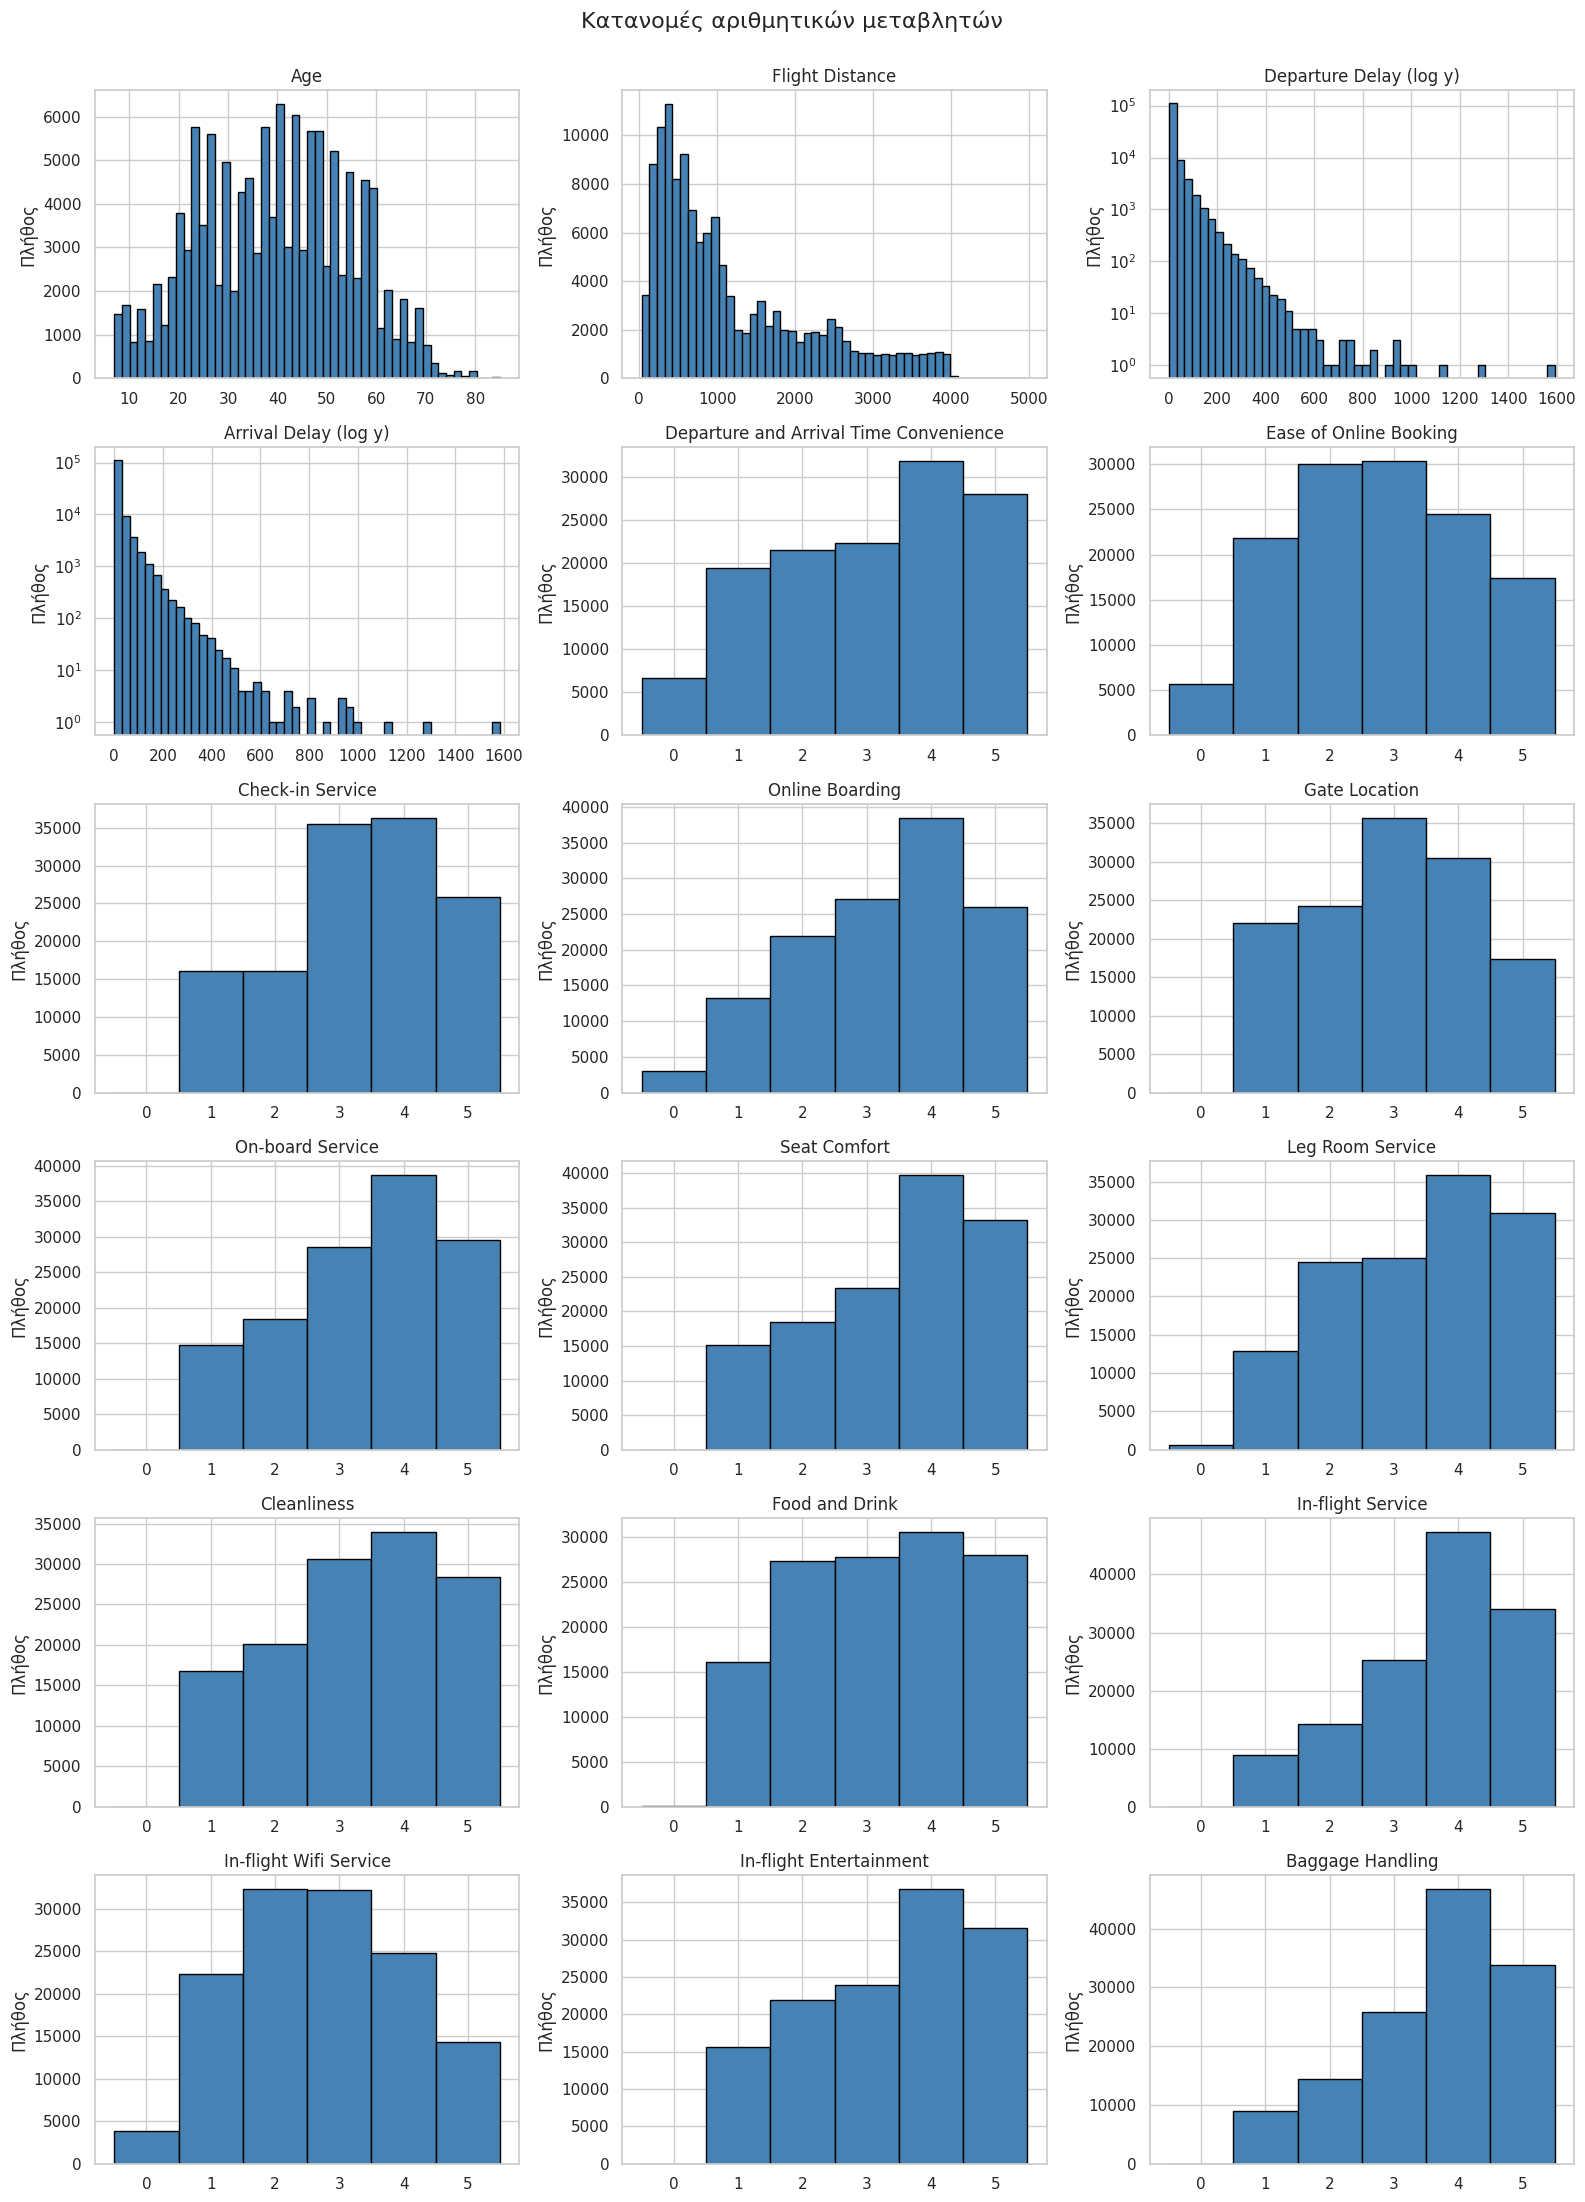

In [15]:
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
for ax, col in zip(axes.flat, num_cols):
    if df[col].nunique() <= 6:
        ax.hist(df[col], bins=np.arange(-0.5, 6.5, 1), edgecolor='black', color='steelblue')
        ax.set_xticks(range(6))
    else:
        ax.hist(df[col].dropna(), bins=50, edgecolor='black', color='steelblue')
    if 'Delay' in col:
        ax.set_yscale('log')
        col_title = col + ' (log y)'
    else:
        col_title = col
    ax.set_title(col_title)
    ax.set_ylabel('Πλήθος')
plt.suptitle('Κατανομές αριθμητικών μεταβλητών', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

**Παρατηρήσεις στα ιστογράμματα:**


* Age: Οι περισσότεροι επιβάτες είναι μεταξύ 25 και 60.
* Flight Distance: Οι περισσότερες πτήσεις είναι μικρές.
* Departure Delay και Arrival Delay: Σχεδόν όλες οι πτήσεις έφυγαν και έφτασαν στην ώρα τους ή με λίγη καθυστέρηση. Υπάρχουν όμως και κάποιες λίγες πτήσεις με πολύ μεγάλη καθυστέρηση. Επειδή είναι τόσο λίγες, χρησιμοποιήσαμε λογαριθμικό άξονα για να φαίνονται.
* Βαθμολογίες (0–5): Στις περισσότερες υπηρεσίες οι επιβάτες βάζουν κυρίως 4 και 5, δηλαδή είναι γενικά ευχαριστημένοι. Δύο υπηρεσίες πάνε χειρότερα: η online κράτηση και το Wifi, όπου οι περισσότεροι βάζουν 2 ή 3. Το 0 σημαίνει ότι ο επιβάτης δεν απάντησε, και είναι λίγες τέτοιες περιπτώσεις.

### Ραβδογράμματα

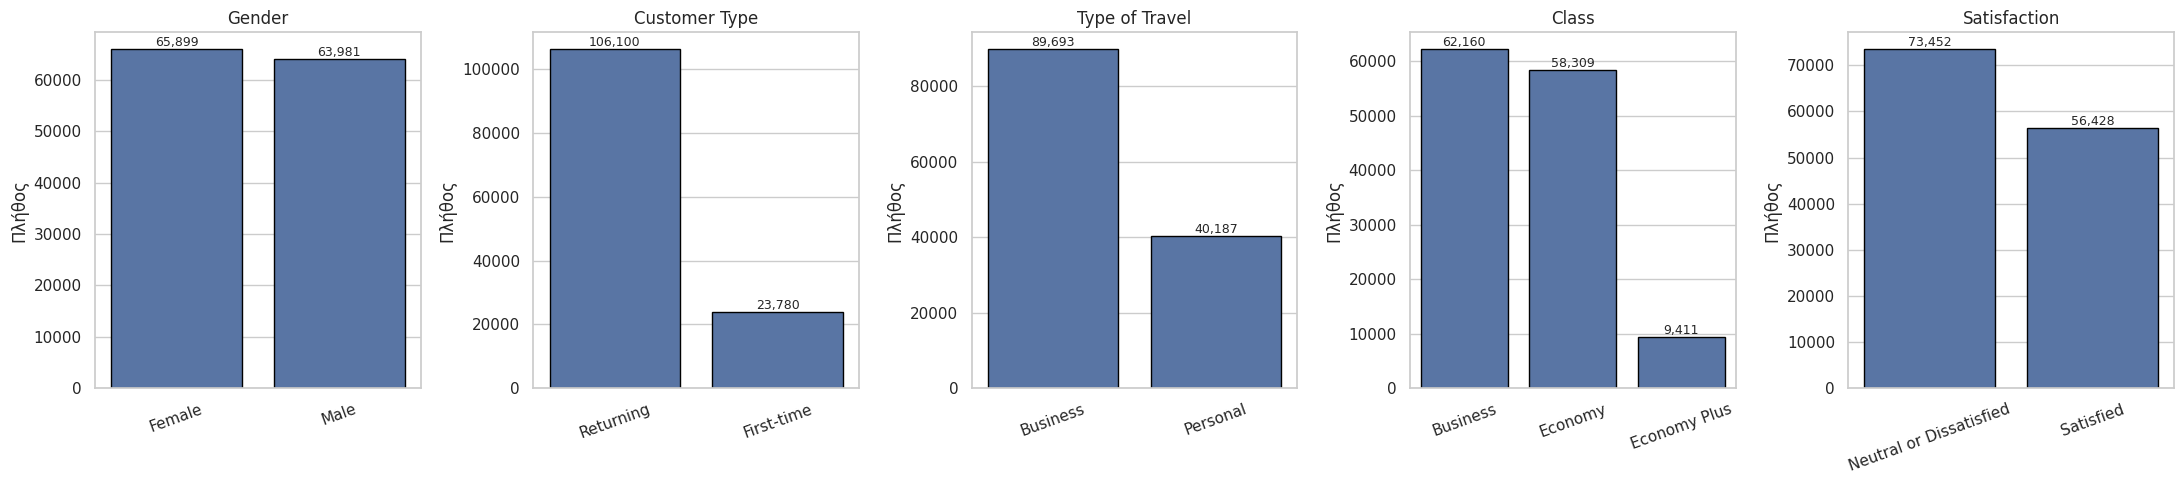

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, col in zip(axes, cat_cols):
    counts = df[col].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, edgecolor='black')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Πλήθος')
    ax.tick_params(axis='x', rotation=20)
    for i, v in enumerate(counts.values):
        ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

**Συμπέρασμα για τις κλάσεις:**

* Από το ραβδόγραμμα του Satisfaction βλέπουμε ότι υπάρχουν 73.452 επιβάτες ουδέτεροι ή δυσαρεστημένοι και 56.428 ικανοποιημένοι.

* Οι δυσαρεστημένοι είναι λίγο περισσότεροι, αλλά η διαφορά είναι μικρή. Άρα οι κλάσεις είναι σχεδόν ισορροπημένες.

* Για τις υπόλοιπες κατηγορικές: άντρες και γυναίκες είναι περίπου ίσοι. Οι περισσότεροι επιβάτες είναι πελάτες που έχουν ξαναταξιδέψει με την εταιρεία (Returning) και ταξιδεύουν για δουλειά (Business). Η θέση Economy Plus είναι η πιο σπάνια.

## Ερώτημα 1.2 – Κωδικοποίηση κατηγορικών μεταβλητών

**Βήμα 1:** αφαιρούμε τη στήλη ID. Για τις 393 τιμές που λείπουν στο Arrival Delay, βάζουμε την τιμή του Departure Delay της ίδιας πτήσης, επειδή οι δύο καθυστερήσεις είναι σχεδόν ίδιες.

In [17]:
print('Συσχέτιση Departure - Arrival Delay:',
      round(df['Departure Delay'].corr(df['Arrival Delay']), 3))

df_enc = df.drop(columns=['ID']).copy()
df_enc['Arrival Delay'] = df_enc['Arrival Delay'].fillna(df_enc['Departure Delay'])
print('Τιμές που λείπουν τώρα:', df_enc.isna().sum().sum())

Συσχέτιση Departure - Arrival Delay: 0.965
Τιμές που λείπουν τώρα: 0


**Βήμα 2:** Gender, Customer Type, Type of Travel και Satisfaction έχουν μόνο δύο τιμές, οπότε αρκεί μία στήλη με 0/1.

In [18]:
binary_maps = {
    'Gender':         {'Female': 0, 'Male': 1},
    'Customer Type':  {'First-time': 0, 'Returning': 1},
    'Type of Travel': {'Personal': 0, 'Business': 1},
    'Satisfaction':   {'Neutral or Dissatisfied': 0, 'Satisfied': 1},
}
for col, mapping in binary_maps.items():
    df_enc[col] = df_enc[col].map(mapping)

df_enc[list(binary_maps)].head()

,Gender,Customer Type,Type of Travel,Satisfaction
0,1,0,1,0
1,0,1,1,1
2,1,1,1,1
3,1,1,1,1
4,0,1,1,1


**Βήμα 3:** Η μεταβλητή Class έχει 3 τιμές, οπότε μπορεί να κωδικοποιηθεί με δύο τρόπους.

1. **Ordinal encoding:** Economy = 0, Economy Plus = 1, Business = 2.
2. **One-hot encoding:** τρεις στήλες 0/1, μία για κάθε θέση.


In [19]:
#Ordinal encoding
class_ordinal = df_enc['Class'].map({'Economy': 0, 'Economy Plus': 1, 'Business': 2})
pd.DataFrame({'Class': df_enc['Class'], 'Ordinal': class_ordinal}).drop_duplicates().sort_values('Ordinal')

,Class,Ordinal
12,Economy,0
23,Economy Plus,1
0,Business,2


In [20]:
#One-hot encoding
pd.get_dummies(df_enc['Class'], prefix='Class', dtype=int).join(df_enc['Class']).drop_duplicates()

,Class_Business,Class_Economy,Class_Economy Plus,Class
0,1,0,0,Business
12,0,1,0,Economy
23,0,0,1,Economy Plus


**Σημείωση:** Κρατάμε το one-hot. Με το ordinal, το μοντέλο θα θεωρούσε ότι η Business απέχει από την Economy διπλάσια απόσταση από την Economy Plus, κάτι που δεν ισχύει απαραίτητα. Επίσης, έτσι όλες οι κατηγορικές στήλες είναι 0/1.

In [21]:
df_enc = pd.get_dummies(df_enc, columns=['Class'], prefix='Class', dtype=int)
df_enc.head()

,Gender,Age,Customer Type,Type of Travel,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction,Class_Business,Class_Economy,Class_Economy Plus
0,1,48,0,1,821,2,5.0,3,3,4,3,3,3,5,2,5,5,5,3,5,5,0,1,0,0
1,0,35,1,1,821,26,39.0,2,2,3,5,2,5,4,5,5,3,5,2,5,5,1,1,0,0
2,1,41,1,1,853,0,0.0,4,4,4,5,4,3,5,3,5,5,3,4,3,3,1,1,0,0
3,1,50,1,1,1905,0,0.0,2,2,3,4,2,5,5,5,4,4,5,2,5,5,1,1,0,0
4,0,49,1,1,3470,0,1.0,3,3,3,5,3,3,4,4,5,4,3,3,3,3,1,1,0,0


## Ερώτημα 1.3 – Numpy arrays και διαχωρισμός Train-Test

In [22]:
feature_names = df_enc.drop(columns=['Satisfaction']).columns.tolist()

x = df_enc[feature_names].to_numpy(dtype=np.float64)
y = df_enc['Satisfaction'].to_numpy()

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

print('x_train:', x_train.shape, ' x_test:', x_test.shape)

x_train: (90916, 24)  x_test: (38964, 24)


Τα δεδομένα έγιναν Numpy arrays: το x περιέχει τα 24 χαρακτηριστικά κάθε επιβάτη και το y την ικανοποίηση (0 ή 1). Μετά τα χωρίσαμε σε train (70%, 90.916 επιβάτες) και test (30%, 38.964 επιβάτες).

## Ερώτημα 1.4 – Κανονικοποίηση

In [23]:
categorical_features = ['Gender', 'Customer Type', 'Type of Travel'] + [c for c in feature_names if c.startswith('Class_')]
numeric_idx = [i for i, c in enumerate(feature_names) if c not in categorical_features]

print('Κανονικοποιούνται', len(numeric_idx), 'στήλες:', [feature_names[i] for i in numeric_idx])
print('Δεν κανονικοποιούνται:', categorical_features)

scaler = MinMaxScaler()
x_train[:, numeric_idx] = scaler.fit_transform(x_train[:, numeric_idx])
x_test[:, numeric_idx] = scaler.transform(x_test[:, numeric_idx])

Κανονικοποιούνται 18 στήλες: ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']
Δεν κανονικοποιούνται: ['Gender', 'Customer Type', 'Type of Travel', 'Class_Business', 'Class_Economy', 'Class_Economy Plus']


**Αιτιολόγηση κανονικοποίησης:**
* Ο KNN κρίνει πόσο μοιάζουν δύο επιβάτες μετρώντας την απόσταση ανάμεσά τους. Το πρόβλημα είναι ότι οι στήλες έχουν πολύ διαφορετικά νούμερα. Οι βαθμολογίες πάνε από 0 μέχρι 5, ενώ η απόσταση της πτήσης φτάνει μέχρι 5.000. Χωρίς κανονικοποίηση, οι μεταβλητές με μεγάλες τιμές θα επηρέαζαν δυσανάλογα τον υπολογισμό της απόστασης, αγνοώντας τις βαθμολογίες.
* Για τον λόγο αυτό χρησιμοποιούμε Min-Max Scaling, που φέρνει όλες τις αριθμητικές στήλες από 0 έως 1, ώστε να μετράνε όλες το ίδιο. Τις κατηγορικές δεν τις πειράζουμε, γιατί είναι ήδη 0 και 1.
* Τα όρια (min και max) υπολογίζονται μόνο από το train και εφαρμόζονται μετά και στο test.

## Ερώτημα 1.5 – Ταξινομητής KNN

Δοκιμάζουμε k = 3, 5, 15, 51, 151 και N, με δύο τρόπους ψηφοφορίας: uniform και distance. Σύνολο 12 συνδυασμοί.

Για k = N χρησιμοποιούμε τη συνάρτηση knn_predict_all_neighbors, γιατί ο κανονικός KNN δεν χωράει στη μνήμη του Colab.

In [24]:
def knn_predict_all_neighbors(x_train, y_train, x_query, weights, batch_size=1000):
    classes = np.unique(y_train)

    if weights == 'uniform':
        majority = classes[np.argmax([np.sum(y_train == c) for c in classes])]
        return np.full(len(x_query), majority)

    one_hot = (y_train[:, None] == classes[None, :]).astype(np.float64)
    preds = np.empty(len(x_query), dtype=y_train.dtype)
    for start in range(0, len(x_query), batch_size):
        d = euclidean_distances(x_query[start:start + batch_size], x_train)
        zero = (d == 0)
        with np.errstate(divide='ignore'):
            w = 1.0 / d
        has_zero = zero.any(axis=1)
        w[has_zero] = zero[has_zero].astype(np.float64)
        preds[start:start + batch_size] = classes[np.argmax(w @ one_hot, axis=1)]
    return preds

In [25]:
N = x_train.shape[0]
k_values = [3, 5, 15, 51, 151, N]
weight_options = ['uniform', 'distance']

results = []
for k in k_values:
    for w in weight_options:
        start = time.time()
        if k == N:
            y_pred_train = knn_predict_all_neighbors(x_train, y_train, x_train, w)
            y_pred_test = knn_predict_all_neighbors(x_train, y_train, x_test, w)
        else:
            knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean', n_jobs=-1)
            knn.fit(x_train, y_train)
            y_pred_train = knn.predict(x_train)
            y_pred_test = knn.predict(x_test)

        train_acc = accuracy_score(y_train, y_pred_train)
        test_acc = accuracy_score(y_test, y_pred_test)
        results.append({'k': k if k != N else f'N = {N}', 'weights': w,
                        'Train Accuracy': train_acc, 'Test Accuracy': test_acc})
        print(f'k={k:>6}, weights={w:8s} -> train={train_acc:.4f}, test={test_acc:.4f}  ({time.time()-start:.0f} s)')

results_df = pd.DataFrame(results)

k=     3, weights=uniform  -> train=0.9594, test=0.9276  (76 s)
k=     3, weights=distance -> train=1.0000, test=0.9277  (75 s)
k=     5, weights=uniform  -> train=0.9488, test=0.9298  (76 s)
k=     5, weights=distance -> train=1.0000, test=0.9299  (77 s)
k=    15, weights=uniform  -> train=0.9345, test=0.9286  (76 s)
k=    15, weights=distance -> train=1.0000, test=0.9292  (76 s)
k=    51, weights=uniform  -> train=0.9227, test=0.9196  (79 s)
k=    51, weights=distance -> train=1.0000, test=0.9212  (79 s)
k=   151, weights=uniform  -> train=0.9090, test=0.9074  (88 s)
k=   151, weights=distance -> train=1.0000, test=0.9092  (89 s)
k= 90916, weights=uniform  -> train=0.5663, test=0.5638  (0 s)
k= 90916, weights=distance -> train=1.0000, test=0.8074  (218 s)


In [28]:
best = results_df['Test Accuracy'].idxmax()
(results_df.style
    .format({'Train Accuracy': '{:.4f}', 'Test Accuracy': '{:.4f}'})
    .set_caption('Ακρίβεια KNN σε Train και Test για κάθε συνδυασμό'))

,k,weights,Train Accuracy,Test Accuracy
0,3,uniform,0.9594,0.9276
1,3,distance,1.0000,0.9277
2,5,uniform,0.9488,0.9298
3,5,distance,1.0000,0.9299
4,15,uniform,0.9345,0.9286
5,15,distance,1.0000,0.9292
6,51,uniform,0.9227,0.9196
7,51,distance,1.0000,0.9212
8,151,uniform,0.9090,0.9074
9,151,distance,1.0000,0.9092


In [29]:
print('Καλύτερος συνδυασμός (με βάση το Test Accuracy):')
results_df.loc[[best]]

Καλύτερος συνδυασμός (με βάση το Test Accuracy):


,k,weights,Train Accuracy,Test Accuracy
3,5,distance,1.0,0.929935


**Σχολιασμός αποτελεσμάτων:**

* Καλύτερος συνδυασμός: Τη μεγαλύτερη ακρίβεια στο test (περίπου 93%) την πέτυχε ο KNN με k = 5 και βάρη distance. Πολύ κοντά βρίσκονται και τα k = 5 με uniform και k = 15.
* Μικρές τιμές του k (3, 5, 15): Δίνουν τα καλύτερα αποτελέσματα, γιατί το μοντέλο αποφασίζει με βάση λίγους επιβάτες που μοιάζουν πραγματικά με αυτόν που εξετάζουμε.
* Μεγάλες τιμές του k (51, 151): Η ακρίβεια μειώνεται σταδιακά, γιατί στην απόφαση συμμετέχουν και επιβάτες που διαφέρουν αρκετά.
* k = N με uniform: όλοι οι επιβάτες ψηφίζουν ισότιμα, προβλέπει για όλους την κλάση που υπερισχύει (Neutral or Dissatisfied). Η ακρίβεια (περίπου 56%) είναι ίση με το ποσοστό αυτής της κλάσης, άρα το μοντέλο δεν έχει μάθει κάτι χρήσιμο.
* k = N με distance: Η ακρίβεια είναι καλύτερη (περίπου 81%), επειδή οι κοντινοί επιβάτες έχουν μεγαλύτερο βάρος. Η επίδρασή τους όμως περιορίζεται από τους χιλιάδες μακρινούς, γι' αυτό παραμένει χαμηλότερη από τις μικρές τιμές του k.
* Train Accuracy 100% με distance: Κάθε επιβάτης του train έχει πλησιέστερο γείτονα τον εαυτό του, με απόσταση 0, οπότε η πρόβλεψη είναι πάντα σωστή. Γι' αυτό τη σύγκριση των μοντέλων την κάνουμε με βάση το test.

Συμπέρασμα: Για το σύστημα πρόβλεψης της DWS Airlines προτείνεται ο KNN με k = 5 και βάρη distance, που προβλέπει σωστά την ικανοποίηση περίπου 93 στους 100 νέους επιβάτες.

# Μέρος 2 – Πρόβλεψη Χρονοσειρών

In [30]:
ticker_symbol = 'DX-Y.NYB'
usd = yf.Ticker(ticker_symbol).history(period='10y')
usd.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2016-10-28 00:00:00-04:00,98.919998,98.940002,98.239998,98.349998,0,0.0,0.0
2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997,0,0.0,0.0
2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997,0,0.0,0.0
2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002,0,0.0,0.0
2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004,0,0.0,0.0


In [32]:
df_usd = usd.drop(columns=['Volume', 'Dividends', 'Stock Splits'], errors='ignore').reset_index()
df_usd['Date'] = df_usd['Date'].dt.tz_localize(None).dt.normalize()
print('Από', df_usd['Date'].min().date(), 'έως', df_usd['Date'].max().date(), '-', len(df_usd), 'ημέρες συναλλαγών')
df_usd

Από 2016-10-28 έως 2026-10-28 - 2514 ημέρες συναλλαγών


,Date,Open,High,Low,Close
0,2016-10-28,98.919998,98.940002,98.239998,98.349998
1,2016-10-31,98.320000,98.699997,98.290001,98.449997
2,2016-11-01,98.389999,98.480003,97.639999,97.699997
3,2016-11-02,97.750000,97.800003,97.180000,97.400002
4,2016-11-03,97.379997,97.459999,97.040001,97.160004
...,...,...,...,...,...
2509,2026-10-22,101.709999,101.879997,101.449997,101.610001
2510,2026-10-23,101.570000,101.849998,101.489998,101.809998
2511,2026-10-26,101.779999,102.059998,101.580002,101.959999
2512,2026-10-27,102.029999,102.400002,101.989998,102.320000


## Ερώτημα 2.1 – Μεταβλητές OHLCV και γράφημα

**Μεταβλητές OHLCV**:

* **Open:** Η τιμή στην αρχή (άνοιγμα) της ημέρας συναλλαγών.
* **High:** Η υψηλότερη τιμή που έπιασε μέσα στην ημέρα.
* **Low:** Η χαμηλότερη τιμή που έπιασε μέσα στην ημέρα.
* **Close:** Η τιμή στο τέλος (κλείσιμο) της ημέρας. Συνήθως αυτή προβλέπουμε.
* **Volume:** Ο όγκος συναλλαγών (πόσα συμβόλαια/μετοχές άλλαξαν χέρια). Για τον δείκτη του δολαρίου είναι 0, γι' αυτό τον αφαιρέσαμε.



In [33]:
price_cols = ['Open', 'High', 'Low', 'Close']
stats = df_usd[price_cols].agg(['mean', 'std']).T
stats.columns = ['Μέση τιμή', 'Τυπική απόκλιση']
stats.round(3)

,Μέση τιμή,Τυπική απόκλιση
Open,98.798,4.971
High,99.099,5.019
Low,98.508,4.915
Close,98.808,4.972


Οι τέσσερις μεταβλητές έχουν σχεδόν ίδια μέση τιμή, περίπου 98,8, και σχεδόν ίδια τυπική απόκλιση, περίπου 5. Αυτό είναι λογικό, γιατί μέσα σε μία ημέρα το δολάριο αλλάζει πολύ λίγο, οπότε οι τιμές Open, High, Low και Close είναι πολύ κοντά μεταξύ τους.

In [34]:
fig = px.line(df_usd, x='Date', y=['High', 'Low', 'Close'],
              title='US Dollar Index (DX-Y.NYB) – High, Low, Close τα τελευταία 10 χρόνια')
fig.update_layout(width=1300, height=650, xaxis_title='Ημερομηνία', yaxis_title='Τιμή δείκτη',
                  legend_title='Μεταβλητή', template='plotly_white', hovermode='x unified')
fig.show()

## Ερώτημα 2.2 – Στάσιμες ή μη στάσιμες

Από το γράφημα φαίνεται ότι οι χρονοσειρές High, Low και Close είναι μη στάσιμες. Η τιμή του δολαρίου δεν κινείται γύρω από ένα σταθερό επίπεδο, αλλά έχει περιόδους με έντονη άνοδο και περιόδους με πτώση. Έτσι η μέση τιμή αλλάζει ανάλογα με την περίοδο που εξετάζουμε.

## Ερώτημα 2.3 – Έλεγχοι ADF και KPSS

In [35]:
def stationarity_tests(data, cols):
    rows = []
    for col in cols:
        series = data[col].dropna()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            adf_p = adfuller(series)[1]
            kpss_p = kpss(series, regression='c', nlags='auto')[1]
        verdict = ('Στάσιμη' if (adf_p < 0.05 and kpss_p >= 0.05) else
                   'Μη στάσιμη' if (adf_p >= 0.05 and kpss_p < 0.05) else 'Ασαφές')
        rows.append({'Μεταβλητή': col, 'ADF p-value': round(adf_p, 4),
                     'KPSS p-value': round(kpss_p, 4), 'Συμπέρασμα': verdict})
    return pd.DataFrame(rows)

stationarity_tests(df_usd, ['High', 'Low', 'Close'])

,Μεταβλητή,ADF p-value,KPSS p-value,Συμπέρασμα
0,High,0.3424,0.01,Μη στάσιμη
1,Low,0.2967,0.01,Μη στάσιμη
2,Close,0.3366,0.01,Μη στάσιμη


**Συμπέρασμα:** Για να είναι μια σειρά μη στάσιμη, πρέπει το ADF να βγάλει πάνω από 0,05 και το KPSS κάτω από 0,05.

Στις High, Low και Close το ADF βγάζει περίπου 0,3 και το KPSS 0,01. Άρα και τα δύο τεστ δείχνουν ότι οι σειρές είναι μη στάσιμες, όπως είδαμε και στο γράφημα 2.2.

## Ερώτημα 2.4 – Διαχωρισμός Train-Test

Σε χρονοσειρές δεν παίρνουμε τυχαία τα δεδομένα. Το train πρέπει να είναι το παρελθόν και το test το μέλλον. Παίρνουμε λοιπόν τις πρώτες 70% ημέρες για train και τις υπόλοιπες 30% για test.


In [36]:
TRAIN_SIZE = 0.7

def train_test_split_ts(data, H):
    num_train = int(len(data) * TRAIN_SIZE)
    train_df = data.iloc[:num_train]
    test_df = data.iloc[num_train - H:]
    return train_df, test_df

train_df, test_df = train_test_split_ts(df_usd, H=0)
print(f'Train: {len(train_df)} ημέρες ({train_df.Date.min().date()} έως {train_df.Date.max().date()})')
print(f'Test:  {len(test_df)} ημέρες ({test_df.Date.min().date()} έως {test_df.Date.max().date()})')

Train: 1759 ημέρες (2016-10-28 έως 2023-10-26)
Test:  755 ημέρες (2023-10-27 έως 2026-10-28)


## Ερώτημα 2.5 – Linear Regression

In [38]:
def construct_timeframes(data, H, feature_cols, target_col, future_cols=None):
    inputs = data[feature_cols].to_numpy(dtype=np.float64)
    x = np.array([inputs[i - H:i].flatten() for i in range(H, len(data))])
    if future_cols:
        future = data[future_cols].to_numpy(dtype=np.float64)[H:]
        x = np.hstack([x, future])
    y = data[target_col].to_numpy(dtype=np.float64)[H:]
    return x, y

In [39]:
H_values = [1, 5, 15, 30]

def run_linear_regression(data, H, feature_cols, target_col, future_cols=None, log_returns=False):
    train_df, test_df = train_test_split_ts(data, H)
    x_train, y_train = construct_timeframes(train_df, H, feature_cols, target_col, future_cols)
    x_test, y_test = construct_timeframes(test_df, H, feature_cols, target_col, future_cols)

    model = LinearRegression().fit(x_train, y_train)
    pred_train, pred_test = model.predict(x_train), model.predict(x_test)

    if log_returns:
        pred_train = train_df['Prev_Close'].to_numpy()[H:] * np.exp(pred_train)
        pred_test = test_df['Prev_Close'].to_numpy()[H:] * np.exp(pred_test)
        y_train = train_df['Close_Price'].to_numpy()[H:]
        y_test = test_df['Close_Price'].to_numpy()[H:]

    return {
        'H': H,
        'Train MAE': mean_absolute_error(y_train, pred_train),
        'Test MAE': mean_absolute_error(y_test, pred_test),
        'train_dates': train_df['Date'].iloc[H:].to_numpy(), 'y_train': y_train, 'pred_train': pred_train,
        'test_dates': test_df['Date'].iloc[H:].to_numpy(), 'y_test': y_test, 'pred_test': pred_test,
    }

def summarize(runs, name):
    return pd.DataFrame([{'Μοντέλο': name, 'H': r['H'], 'Train MAE': r['Train MAE'], 'Test MAE': r['Test MAE']}
                         for r in runs])

In [42]:
runs_abs = [run_linear_regression(df_usd, H, price_cols, 'Close') for H in H_values]
mae_abs = summarize(runs_abs, 'Απόλυτες τιμές')

_tr, _te = train_test_split_ts(df_usd, 1)
naive_train = mean_absolute_error(_tr['Close'].iloc[1:], _tr['Close'].iloc[:-1])
naive_test = mean_absolute_error(_te['Close'].iloc[1:], _te['Close'].iloc[:-1])
print(f'Naive: Train MAE = {naive_train:.4f}, Test MAE = {naive_test:.4f}')

mae_abs.round(4)

Naive: Train MAE = 0.3099, Test MAE = 0.3081


,Μοντέλο,H,Train MAE,Test MAE
0,Απόλυτες τιμές,1,0.3104,0.3095
1,Απόλυτες τιμές,5,0.3100,0.3086
2,Απόλυτες τιμές,15,0.3041,0.3161
3,Απόλυτες τιμές,30,0.3000,0.3245


In [41]:
plot_df = mae_abs.melt(id_vars='H', value_vars=['Train MAE', 'Test MAE'], var_name='Σύνολο', value_name='MAE')
plot_df['H'] = 'H = ' + plot_df['H'].astype(str)
fig = px.bar(plot_df, x='H', y='MAE', color='Σύνολο', barmode='group', text_auto='.3f',
             title='Linear Regression – MAE στο Train και στο Test για κάθε μέγεθος παραθύρου H')
fig.add_hline(y=naive_test, line_dash='dash', line_color='black', annotation_text='Naive (Test)')
fig.update_layout(width=1000, height=550, template='plotly_white', xaxis_title='Μέγεθος παραθύρου',
                  yaxis_title='MAE (μονάδες δείκτη)')
fig.show()

**Συμπεράσματα:**

* Το μοντέλο προβλέπει την τιμή του δολαρίου με μικρό λάθος, περίπου 0,31 μονάδες (περίπου 0,3%).
* Το καλύτερο αποτέλεσμα στο test το δίνει το H = 5.
* Όσο μεγαλώνει το H, το μοντέλο τα πάει καλύτερα στο train αλλά χειρότερα στο test. Άρα οι περισσότερες μέρες ιστορικού δεν βοηθούν.
* Το μοντέλο έχει σχεδόν το ίδιο λάθος με το Naive, δηλαδή με το να προβλέπουμε ότι η τιμή της επόμενης ημέρας θα είναι ίδια με τη σημερινή. Αυτό σημαίνει ότι το μοντέλο στην ουσία δεν προβλέπει κάτι καινούργιο, απλώς επαναλαμβάνει την τελευταία τιμή του δολαρίου.

## Ερώτημα 2.6 – Προβλέψεις για H = 30

In [43]:
def plot_predictions(run, title, last_n_train=30):
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=run['train_dates'][-last_n_train:], y=run['y_train'][-last_n_train:],
                             name='Train (πραγματικό)', line=dict(color='royalblue', width=2)))
    fig.add_trace(go.Scatter(x=run['train_dates'][-last_n_train:], y=run['pred_train'][-last_n_train:],
                             name='Train (πρόβλεψη)', line=dict(color='orange', width=2)))
    fig.add_trace(go.Scatter(x=run['test_dates'], y=run['y_test'],
                             name='Test (πραγματικό)', line=dict(color='royalblue', width=2, dash='dot')))
    fig.add_trace(go.Scatter(x=run['test_dates'], y=run['pred_test'],
                             name='Test (πρόβλεψη)', line=dict(color='#E63946', width=2)))
    fig.add_vline(x=run['test_dates'][0], line_dash='dash', line_color='black')
    fig.update_layout(title=title, width=1300, height=600, template='plotly_white',
                      xaxis_title='Ημερομηνία', yaxis_title='Close', hovermode='x unified',
                      legend=dict(x=0.01, y=0.99))
    fig.show()

run_h30 = runs_abs[-1]
plot_predictions(run_h30, 'Linear Regression (H=30) – πραγματικές τιμές και προβλέψεις του Close')

In [45]:
zoom = slice(0, 40)
fig = go.Figure()
fig.add_trace(go.Scatter(x=run_h30['test_dates'][zoom], y=run_h30['y_test'][zoom], name='Πραγματικό', mode='lines+markers'))
fig.add_trace(go.Scatter(x=run_h30['test_dates'][zoom], y=run_h30['pred_test'][zoom], name='Πρόβλεψη', mode='lines+markers'))
fig.update_layout(title='Πρώτες 40 ημέρες του test (H=30)', width=1300, height=500,
                  template='plotly_white', xaxis_title='Ημερομηνία', yaxis_title='Close')
fig.show()

**Συμπεράσματα:**

* Από μακριά, οι προβλέψεις φαίνονται σχεδόν ίδιες με τις πραγματικές, τόσο στο train όσο και στο test.
* Αν όμως κάνουμε zoom, βλέπουμε ότι η γραμμή της πρόβλεψης είναι η πραγματική γραμμή μετατοπισμένη μία ημέρα προς τα δεξιά. Δηλαδή όταν το δολάριο ανεβαίνει ή πέφτει μια μέρα, η πρόβλεψη ανεβαίνει ή πέφτει την επόμενη.
* Αυτό σημαίνει ότι το μοντέλο δεν προβλέπει πραγματικά τις αλλαγές της τιμής, απλώς ακολουθεί την τιμή της προηγούμενης ημέρας.

## Ερώτημα 2.7 – Log-Returns

In [46]:
df_lr = df_usd.copy()
df_lr[price_cols] = np.log(df_usd[price_cols] / df_usd[price_cols].shift(1))
df_lr['Close_Price'] = df_usd['Close']
df_lr['Prev_Close'] = df_usd['Close'].shift(1)
df_lr = df_lr.dropna().reset_index(drop=True)
df_lr.head()

,Date,Open,High,Low,Close,Close_Price,Prev_Close
0,2016-10-31,-0.006084,-0.002429,0.000509,0.001016,98.449997,98.349998
1,2016-11-01,0.000712,-0.002231,-0.006635,-0.007647,97.699997,98.449997
2,2016-11-02,-0.006526,-0.006929,-0.004722,-0.003075,97.400002,97.699997
3,2016-11-03,-0.003792,-0.003483,-0.001442,-0.002467,97.160004,97.400002
4,2016-11-04,-0.002262,-0.001129,-0.001547,-0.000927,97.070000,97.160004


In [52]:
stationarity_tests(df_lr, ['High', 'Low', 'Close'])

,Μεταβλητή,ADF p-value,KPSS p-value,Συμπέρασμα
0,High,0.0,0.1,Στάσιμη
1,Low,0.0,0.1,Στάσιμη
2,Close,0.0,0.1,Στάσιμη


In [53]:
runs_lr = [run_linear_regression(df_lr, H, price_cols, 'Close', log_returns=True) for H in H_values]
mae_lr = summarize(runs_lr, 'Log-Returns')

comparison = pd.concat([mae_abs, mae_lr])
comparison.pivot(index='H', columns='Μοντέλο', values=['Train MAE', 'Test MAE']).round(4)

Train MAE                   Test MAE               
Μοντέλο Log-Returns Απόλυτες τιμές Log-Returns Απόλυτες τιμές
H                                                            
1            0.3097         0.3104      0.3089         0.3095
5            0.3089         0.3100      0.3080         0.3086
15           0.3039         0.3041      0.3153         0.3161
30           0.2991         0.3000      0.3234         0.3245

In [54]:
plot_df = comparison.copy()
plot_df['H'] = 'H = ' + plot_df['H'].astype(str)
fig = px.bar(plot_df, x='H', y='Test MAE', color='Μοντέλο', barmode='group', text_auto='.4f',
             title='Σύγκριση Test MAE: Απόλυτες τιμές vs Log-Returns')
fig.add_hline(y=naive_test, line_dash='dash', line_color='black', annotation_text='Naive (Test)')
fig.update_layout(width=1000, height=550, template='plotly_white')
fig.show()

**Συμπεράσματα:**
* Μετά τον μετασχηματισμό log-returns οι χρονοσειρές έγιναν στάσιμες, όπως δείχνουν τα τεστ ADF και KPSS.
* Με τα log-returns το MAE στο test είναι λίγο μικρότερο από το 2.5 για όλα τα H, αλλά η διαφορά είναι πολύ μικρή.
* Το καλύτερο αποτέλεσμα το δίνει πάλι το H = 5, και όσο μεγαλώνει το H το test χειροτερεύει, όπως και στο 2.5.
* Η βελτίωση είναι μικρή γιατί οι αλλαγές του δολαρίου από μέρα σε μέρα είναι σχεδόν τυχαίες. Έτσι το μοντέλο προβλέπει αλλαγή κοντά στο 0 και η πρόβλεψη καταλήγει πάλι κοντά στη χθεσινή τιμή.

## Ερώτημα 2.8 – Granger Causality

In [55]:
max_lag = 30
train_lr, _ = train_test_split_ts(df_lr, H=0)
data = train_lr[['Close', 'Open']]

with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
    warnings.simplefilter('ignore')
    gc_results = grangercausalitytests(data, maxlag=max_lag)

granger_df = pd.DataFrame({
    'Lag': list(range(1, max_lag + 1)),
    'P-value': [gc_results[lag][0]['ssr_ftest'][1] for lag in range(1, max_lag + 1)],
})
granger_df['Σημαντικό (p<0.05)'] = granger_df['P-value'] < 0.05

significant_lags = granger_df.loc[granger_df['Σημαντικό (p<0.05)'], 'Lag'].tolist()
print('Σημαντικά lags:', significant_lags)
granger_df.round(4)

Σημαντικά lags: [5]


,Lag,P-value,Σημαντικό (p<0.05)
0,1,0.2160,False
1,2,0.8227,False
2,3,0.5149,False
3,4,0.7861,False
4,5,0.0218,True
5,6,0.6361,False
6,7,0.7544,False
7,8,0.3855,False
8,9,0.2922,False
9,10,0.4926,False


**Συμπεράσματα:**

* Μόνο στο lag 5 το p-value είναι κάτω από 0,05. Σε όλα τα άλλα lags είναι πάνω.
* Άρα το Open γενικά δεν βοηθά πολύ στην πρόβλεψη του Close.
* Το μόνο σημαντικό χρονικό βήμα είναι το 5, δηλαδή οι τελευταίες 5 μέρες.

## Ερώτημα 2.9 – S&P500, ημερολόγιο και αργίες

In [57]:
sp500 = yf.Ticker('^GSPC').history(period='10y')[['Close']].reset_index()
sp500['Date'] = sp500['Date'].dt.tz_localize(None).dt.normalize()
sp500 = sp500.rename(columns={'Close': 'SP500'})

df_feat = df_usd.merge(sp500, on='Date', how='left')
print('Ημέρες χωρίς τιμή S&P500 (συμπληρώνονται με την προηγούμενη):', df_feat['SP500'].isna().sum())
df_feat['SP500'] = df_feat['SP500'].ffill().bfill()

df_feat['DayOfWeek'] = df_feat['Date'].dt.dayofweek
df_feat['Month'] = df_feat['Date'].dt.month
us_holidays = holidays.country_holidays('US', years=range(df_feat['Date'].dt.year.min(), df_feat['Date'].dt.year.max() + 1))
df_feat['Holiday'] = df_feat['Date'].dt.date.map(lambda d: int(d in us_holidays))

print(df_feat['Holiday'].value_counts().rename({0: 'Όχι γιορτή (0)', 1: 'Γιορτή ΗΠΑ (1)'}))
df_feat[df_feat['Holiday'] == 1].head()

Ημέρες χωρίς τιμή S&P500 (συμπληρώνονται με την προηγούμενη): 3
Holiday
Όχι γιορτή (0)    2492
Γιορτή ΗΠΑ (1)      22
Name: count, dtype: int64


,Date,Open,High,Low,Close,SP500,DayOfWeek,Month,Holiday
236,2017-10-09,93.769997,93.839996,93.620003,93.739998,2544.729980,0,10,1
260,2017-11-10,94.500000,94.650002,94.260002,94.389999,2582.300049,4,11,1
487,2018-10-08,95.620003,96.029999,95.589996,95.769997,2884.429932,0,10,1
512,2018-11-12,97.050003,97.690002,96.970001,97.540001,2726.219971,0,11,1
742,2019-10-14,98.360001,98.529999,98.339996,98.449997,2966.149902,0,10,1


In [58]:
lr_cols = price_cols + ['SP500']
df_feat_lr = df_feat.copy()
df_feat_lr[lr_cols] = np.log(df_feat[lr_cols] / df_feat[lr_cols].shift(1))
df_feat_lr['Close_Price'] = df_feat['Close']
df_feat_lr['Prev_Close'] = df_feat['Close'].shift(1)
df_feat_lr = df_feat_lr.dropna().reset_index(drop=True)

df_feat_lr = pd.get_dummies(df_feat_lr, columns=['DayOfWeek', 'Month'], prefix=['DoW', 'Month'],
                            drop_first=True, dtype=int)
future_cols = [c for c in df_feat_lr.columns if c.startswith(('DoW_', 'Month_'))] + ['Holiday']
print('Γνωστά μελλοντικά χαρακτηριστικά:', future_cols)
df_feat_lr.head()

Γνωστά μελλοντικά χαρακτηριστικά: ['DoW_1', 'DoW_2', 'DoW_3', 'DoW_4', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Month_10', 'Month_11', 'Month_12', 'Holiday']


,Date,Open,High,Low,Close,SP500,Holiday,Close_Price,Prev_Close,DoW_1,DoW_2,DoW_3,DoW_4,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,Month_10,Month_11,Month_12
0,2016-10-31,-0.006084,-0.002429,0.000509,0.001016,0.000000,0,98.449997,98.349998,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,2016-11-01,0.000712,-0.002231,-0.006635,-0.007647,-0.006810,0,97.699997,98.449997,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,2016-11-02,-0.006526,-0.006929,-0.004722,-0.003075,-0.006547,0,97.400002,97.699997,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0
3,2016-11-03,-0.003792,-0.003483,-0.001442,-0.002467,-0.004433,0,97.160004,97.400002,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0
4,2016-11-04,-0.002262,-0.001129,-0.001547,-0.000927,-0.001668,0,97.070000,97.160004,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0


In [59]:
runs_feat = [run_linear_regression(df_feat_lr, H, lr_cols, 'Close', future_cols=future_cols, log_returns=True)
             for H in H_values]
mae_feat = summarize(runs_feat, 'Log-Returns + S&P500 + ημερολόγιο')

comparison_all = pd.concat([mae_abs, mae_lr, mae_feat])
comparison_all.pivot(index='H', columns='Μοντέλο', values='Test MAE').round(4)

Μοντέλο,Log-Returns,Log-Returns + S&P500 + ημερολόγιο,Απόλυτες τιμές
H,,,
1,0.3089,0.3095,0.3095
5,0.3080,0.3105,0.3086
15,0.3153,0.3159,0.3161
30,0.3234,0.3281,0.3245


In [60]:
plot_df = comparison_all.copy()
plot_df['H'] = 'H = ' + plot_df['H'].astype(str)
fig = px.bar(plot_df, x='H', y='Test MAE', color='Μοντέλο', barmode='group', text_auto='.4f',
             title='Σύγκριση Test MAE για όλα τα μοντέλα')
fig.add_hline(y=naive_test, line_dash='dash', line_color='black', annotation_text='Naive (Test)')
fig.update_layout(width=1200, height=550, template='plotly_white', legend=dict(orientation='h', y=-0.15))
fig.show()

In [61]:
plot_predictions(runs_feat[-1], 'Log-Returns + S&P500 + ημερολόγιο (H=30) – προβλέψεις σε απόλυτες τιμές')

**Συμπεράσματα:**

* Η προσθήκη του S&P500, της ημέρας, του μήνα και των αργιών δεν βελτίωσε το μοντέλο. Σε όλα τα H το MAE στο test είναι λίγο μεγαλύτερο από το μοντέλο του 2.7 με μόνο log-returns.
* Η διαφορά είναι μεγαλύτερη στο H = 30, γιατί εκεί το μοντέλο έχει πάρα πολλά χαρακτηριστικά και κάνει overfitting.
* Στο γράφημα για H = 30 φαίνεται ότι η πρόβλεψη ακολουθεί πάλι την πραγματική τιμή με καθυστέρηση μίας ημέρας, όπως στο 2.6.
* Άρα ούτε το χρηματιστήριο ούτε το ημερολόγιο βοηθούν να προβλέψουμε την αλλαγή του δολαρίου από μέρα σε μέρα. Οι αργίες μάλιστα είναι πολύ λίγες (22 μέρες), οπότε σχεδόν δεν επηρεάζουν.

